In [1]:
from ase.io import read
from ase.build import make_supercell
from matplotlib import rc
rc("text", usetex=True)
import matplotlib.pylab as pylab
params = {"legend.fontsize": "14", "axes.labelsize": 20, "axes.titlesize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16}
pylab.rcParams.update(params)
import numpy as np
import glob


try:
    from tqdm import tqdm as _tqdm

    _TQDM_AVAILABLE = True
except ImportError:
    _TQDM_AVAILABLE = False


def _progress(iterable, **kwargs):
    """Wrap an iterable with tqdm if available, else return as-is."""
    if _TQDM_AVAILABLE:
        return _tqdm(iterable, **kwargs)
    return iterable

In [ ]:
# load the molecular dynamics trajectory
traj_directory = "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/800_K/"
all_traj_files = glob.glob(traj_directory + "nve_md_*.traj")
traj = []
for i in range(len(all_traj_files)):
    print(f"Loading trajectory file {i+1}/{len(all_traj_files)}: {all_traj_files[i]}")
    traj_name = traj_directory + f"nve_md_{i+1}.traj"
    traj += read(traj_name, index=":")
print("loaded", len(traj), "frames")

# Now loop through the trajectory and computed the averaged position of each atom across the trajectory, taking into account the periodic boundary conditions, and make it into a new ASE Atoms object as the reference structure for the essential dynamics analysis.
averaged_structure = traj[0].copy()
for atom in averaged_structure:
    averaged_structure.positions[atom.index] = np.zeros(3)

for frame in _progress(traj, desc="Computing averaged structure", leave=False):
    for atom in frame:
        fractional_position = np.dot(atom.position, np.linalg.inv(frame.cell))
        fractional_position -= np.round(fractional_position)
        wrapped_position = np.dot(fractional_position, frame.cell)  
        averaged_structure.positions[atom.index] += wrapped_position
averaged_structure.positions /= len(traj)
print("computed averaged structure")

Loading trajectory file 1/52: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/800_K/nve_md_32.traj
Loading trajectory file 2/52: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/800_K/nve_md_24.traj
Loading trajectory file 3/52: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/800_K/nve_md_49.traj
Loading trajectory file 4/52: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/800_K/nve_md_28.traj
Loading trajectory file 5/52: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/800_K/nve_md_12.traj
Loading trajectory file 6/52: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-

computed averaged structure


Computing the mass-weighted atomic displacements. For atom $i$, its time-dependent displacement is $\sqrt{m_i}\Delta\mathbf{r}_i(t)=\sqrt{m_i}\left(\mathbf{r}_i(t)-\langle\mathbf{r}_i\rangle_t\right)$, which is the difference between its instantaneous position the averaged atomic position across the entire trajectory, taking into account the periodic boundary condition. With this definition, $\Delta\mathbf{r}$ essentially captures the fluctuation of atomic positions across the entire simulation trajectory.

In [3]:
# now loop through the trajectory, and for each frame, calculate the displacement of each atom from its position in the equilibrium structure, taking into account the periodic boundary conditions, and normalise the displacement by the square root of the mass of each atom.
atomic_displacements = []
system_energies = []

def compute_atomic_displacements(index,atom):
    ## Calculate displacement from equilibrium position
    ##delta_r = atom.position - equilibrium_structure[index].position

    #calculate displacement from averaged position
    delta_r = atom.position - averaged_structure[index].position
    # Apply periodic boundary conditions
    delta_r -= np.round(delta_r / frame.cell.diagonal()) * frame.cell.diagonal()
    # Normalise by square root of mass
    normalized_displacement = delta_r / np.sqrt(atom.mass)
    return normalized_displacement

for frame in _progress(traj, desc="Compute mass-normalized displacements", leave=False):
    atomic_displacements.append(np.array([compute_atomic_displacements(i, atom) for i, atom in enumerate(frame)]).reshape(-1))
    system_energies.append(frame.get_potential_energy()/frame.get_number_of_atoms())

Compute mass-normalized displacements:   0%|          | 0/100894 [00:00<?, ?it/s]/var/folders/br/04zcp1g56w37cwn0tggh9fjw0000gn/T/ipykernel_57439/4189573841.py:19: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  system_energies.append(frame.get_potential_energy()/frame.get_number_of_atoms())


**Covariance Matrix Computation**

Computing the covariant matrix $\mathbf{C}$ for the displacements, in which the matrix element $C_{i\alpha,j\beta}=\langle\sqrt{m_i m_j}\Delta r_{i\alpha} \Delta r_{j\beta}\rangle$, where the Greek subscript denotes Cartesian direction.

In [4]:
covariance_matrix = np.zeros((averaged_structure.get_number_of_atoms() * 3, averaged_structure.get_number_of_atoms() * 3))
atomic_displacements = np.array(atomic_displacements)

for i in _progress(range(averaged_structure.get_number_of_atoms() * 3), desc="Compute covariance matrix", leave=False):
    dispalacement_i = atomic_displacements[:, i]
    covariance_matrix[i, i+1:] = np.dot(dispalacement_i, atomic_displacements[:, i+1:])/dispalacement_i.shape[0]
    
covariance_matrix += covariance_matrix.T + np.identity(averaged_structure.get_number_of_atoms() * 3)

np.save(traj_directory + "covariance_matrix_from_averaged_structure.npy", covariance_matrix)      

/var/folders/br/04zcp1g56w37cwn0tggh9fjw0000gn/T/ipykernel_57439/2355682770.py:1: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  covariance_matrix = np.zeros((averaged_structure.get_number_of_atoms() * 3, averaged_structure.get_number_of_atoms() * 3))
/var/folders/br/04zcp1g56w37cwn0tggh9fjw0000gn/T/ipykernel_57439/2355682770.py:4: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  for i in _progress(range(averaged_structure.get_number_of_atoms() * 3), desc="Compute covariance matrix", leave=False):
/var/folders/br/04zcp1g56w37cwn0tggh9fjw0000gn/T/ipykernel_57439/2355682770.py:8: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  covariance_matrix += covariance_matrix.T + np.identity(averaged_structure.get_number_of_atoms() * 3)


**Eigenvalue analysis**

Based on the computed covariance matrix $\mathbf{C}$, solve the eigenvalue problem of $\mathbf{C}\mathbf{v}_{k}=\lambda_k\mathbf{v}_k$. 

Plotting the eigenvalue spectrum $\{\lambda_k\}$ in descending order for MD conducted at different temperatures for an inspection.

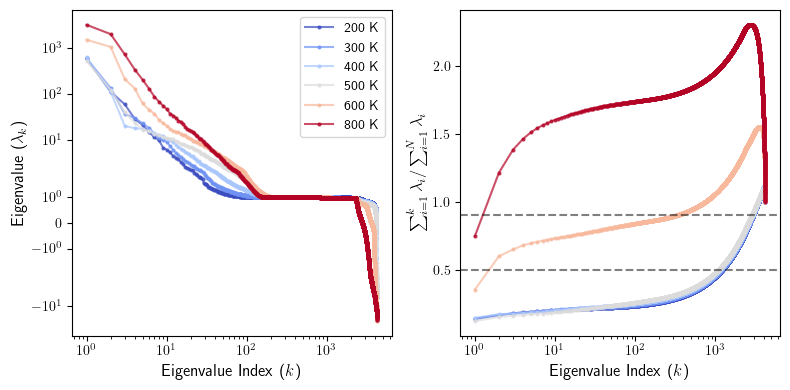

In [9]:
from matplotlib import pyplot as plt
covariance_matrix_200K = np.load("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/200_K/covariance_matrix_from_averaged_structure.npy")
covariance_matrix_300K = np.load("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/300_K/covariance_matrix_from_averaged_structure.npy")
covariance_matrix_400K = np.load("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/400_K/covariance_matrix_from_averaged_structure.npy")
covariance_matrix_500K = np.load("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/500_K/covariance_matrix_from_averaged_structure.npy")
covariance_matrix_600K = np.load("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/600_K/covariance_matrix_from_averaged_structure.npy")
covariance_matrix_800K = np.load("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/800_K/covariance_matrix_from_averaged_structure.npy")

eigenvalues_200K, eigenvectors_200K = np.linalg.eigh(covariance_matrix_200K)
eigenvalues_300K, eigenvectors_300K = np.linalg.eigh(covariance_matrix_300K)
eigenvalues_400K, eigenvectors_400K = np.linalg.eigh(covariance_matrix_400K)
eigenvalues_500K, eigenvectors_500K = np.linalg.eigh(covariance_matrix_500K)
eigenvalues_600K, eigenvectors_600K = np.linalg.eigh(covariance_matrix_600K)
eigenvalues_800K, eigenvectors_800K = np.linalg.eigh(covariance_matrix_800K)

#sort the eigenvectors according to descending order of eigenvalues
eigenvectors_200K = eigenvectors_200K[:, np.argsort(eigenvalues_200K)[::-1]]
eigenvectors_300K = eigenvectors_300K[:, np.argsort(eigenvalues_300K)[::-1]]
eigenvectors_400K = eigenvectors_400K[:, np.argsort(eigenvalues_400K)[::-1]]
eigenvectors_500K = eigenvectors_500K[:, np.argsort(eigenvalues_500K)[::-1]]
eigenvectors_600K = eigenvectors_600K[:, np.argsort(eigenvalues_600K)[::-1]]
eigenvectors_800K = eigenvectors_800K[:, np.argsort(eigenvalues_800K)[::-1]]

#pick a color from the matplotlib colormap for each temperature
colors = plt.cm.coolwarm(np.linspace(0, 1, 7))
color_200K = colors[0]
color_300K = colors[1]
color_400K = colors[2]
color_500K = colors[3]
color_600K = colors[4]
color_800K = colors[6]

fig,ax = plt.subplots(1,2, figsize=(8,4))
ax[0].plot([i+1 for i in range(len(eigenvalues_200K))], np.sort(eigenvalues_200K, axis=None)[::-1],'o-', c=color_200K, label='200 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_300K))], np.sort(eigenvalues_300K, axis=None)[::-1],'o-', c=color_300K, label='300 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_400K))], np.sort(eigenvalues_400K, axis=None)[::-1],'o-', c=color_400K, label='400 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_500K))], np.sort(eigenvalues_500K, axis=None)[::-1],'o-', c=color_500K, label='500 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_600K))], np.sort(eigenvalues_600K, axis=None)[::-1],'o-', c=color_600K, label='600 K',alpha=0.7,markersize=2)
ax[0].plot([i+1 for i in range(len(eigenvalues_800K))], np.sort(eigenvalues_800K, axis=None)[::-1],'o-', c=color_800K, label='800 K',alpha=0.7,markersize=2)

ax[0].set_yscale("symlog")
ax[0].set_xscale("log")
ax[0].set_xlabel('Eigenvalue Index ($k$)', fontsize=12)
ax[0].set_ylabel('Eigenvalue ($\\lambda_k$)', fontsize=12)
ax[0].tick_params(axis='both', which='both', labelsize=10)
ax[0].legend(fontsize=10)

_eigenvalues_200K = np.sort(eigenvalues_200K, axis=None)[::-1]
_eigenvalues_600K = np.sort(eigenvalues_600K, axis=None)[::-1]
_eigenvalues_300K = np.sort(eigenvalues_300K, axis=None)[::-1]
_eigenvalues_500K = np.sort(eigenvalues_500K, axis=None)[::-1]
_eigenvalues_400K = np.sort(eigenvalues_400K, axis=None)[::-1]
_eigenvalues_800K = np.sort(eigenvalues_800K, axis=None)[::-1]

ax[1].plot([i+1 for i in range(len(eigenvalues_200K))], [np.sum(_eigenvalues_200K[:i+1])/np.sum(eigenvalues_200K) for i in range(len(eigenvalues_200K))],'-o', c=color_200K, label='200 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_300K))], [np.sum(_eigenvalues_300K[:i+1])/np.sum(eigenvalues_300K) for i in range(len(eigenvalues_300K))],'-o', c=color_300K, label='300 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_400K))], [np.sum(_eigenvalues_400K[:i+1])/np.sum(eigenvalues_400K) for i in range(len(eigenvalues_400K))],'-o', c=color_400K, label='400 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_500K))], [np.sum(_eigenvalues_500K[:i+1])/np.sum(eigenvalues_500K) for i in range(len(eigenvalues_500K))],'-o', c=color_500K, label='500 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_600K))], [np.sum(_eigenvalues_600K[:i+1])/np.sum(eigenvalues_600K) for i in range(len(eigenvalues_600K))],'-o', c=color_600K, label='600 K',alpha=0.7,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_800K))], [np.sum(_eigenvalues_800K[:i+1])/np.sum(eigenvalues_800K) for i in range(len(eigenvalues_800K))],'-o', c=color_800K, label='800 K',alpha=0.7,markersize=2)
ax[1].set_xscale("log")
#ax[1].set_yscale("log")
ax[1].set_xlabel('Eigenvalue Index ($k$)', fontsize=12)
ax[1].set_ylabel('$\\sum_{i=1}^k \\lambda_i / \\sum_{i=1}^N \\lambda_i$', fontsize=12)
ax[1].tick_params(axis='both', which='both', labelsize=10)
#ax[1].legend()
ax[1].axhline(0.9, c='k', ls='--', alpha=0.5)
ax[1].axhline(0.5, c='k', ls='--', alpha=0.5)
plt.tight_layout()
plt.show()

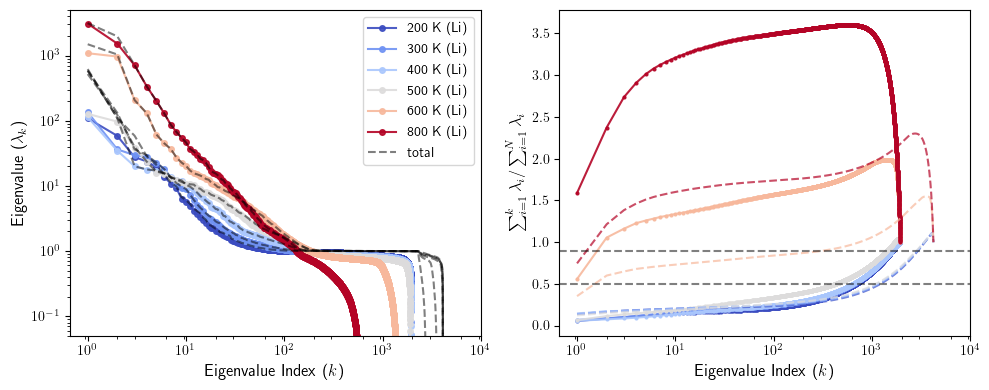

In [55]:
# repeat the above analysis but for particular sublattice only
element = "Li"
input_atom_order = averaged_structure.get_chemical_symbols()
input_atom_oder_dict = {i: symbol for i, symbol in enumerate(input_atom_order)}
indicies = []
indices = [i for i, symbol in input_atom_oder_dict.items() if symbol == element]
indicies = list(np.array([[3*i, 3*i+1, 3*i+2] for i in indices]).reshape(-1))

# now in the covariance matrix, only keep the rows and columns corresponding to the Li sublattice
covariance_matrix_200K_element = covariance_matrix_200K[np.ix_(indicies, indicies)]
covariance_matrix_300K_element = covariance_matrix_300K[np.ix_(indicies, indicies)]
covariance_matrix_400K_element = covariance_matrix_400K[np.ix_(indicies, indicies)]
covariance_matrix_500K_element = covariance_matrix_500K[np.ix_(indicies, indicies)]
covariance_matrix_600K_element = covariance_matrix_600K[np.ix_(indicies, indicies)]
covariance_matrix_800K_element = covariance_matrix_800K[np.ix_(indicies, indicies)]
eigenvalues_200K_element, eigenvectors_200K_element = np.linalg.eigh(covariance_matrix_200K_element)
eigenvalues_300K_element, eigenvectors_300K_element = np.linalg.eigh(covariance_matrix_300K_element)
eigenvalues_400K_element, eigenvectors_400K_element = np.linalg.eigh(covariance_matrix_400K_element)
eigenvalues_500K_element, eigenvectors_500K_element = np.linalg.eigh(covariance_matrix_500K_element)
eigenvalues_600K_element, eigenvectors_600K_element = np.linalg.eigh(covariance_matrix_600K_element)
eigenvalues_800K_element, eigenvectors_800K_element = np.linalg.eigh(covariance_matrix_800K_element)
# sort the eigenvectors according to descending order of eigenvalues
eigenvectors_200K_element = eigenvectors_200K_element[:, np.argsort(eigenvalues_200K_element)[::-1]]
eigenvectors_300K_element = eigenvectors_300K_element[:, np.argsort(eigenvalues_300K_element)[::-1]]
eigenvectors_400K_element = eigenvectors_400K_element[:, np.argsort(eigenvalues_400K_element)[::-1]]
eigenvectors_500K_element = eigenvectors_500K_element[:, np.argsort(eigenvalues_500K_element)[::-1]]
eigenvectors_600K_element = eigenvectors_600K_element[:, np.argsort(eigenvalues_600K_element)[::-1]] 
eigenvectors_800K_element = eigenvectors_800K_element[:, np.argsort(eigenvalues_800K_element)[::-1]]  
# plot the eigenvalues for the Li sublattice only, using a different color for each temperature
fig,ax = plt.subplots(1,2, figsize=(10,4))
ax[0].plot([i+1 for i in range(len(eigenvalues_200K_element))], np.sort(eigenvalues_200K_element, axis=None)[::-1],'o-', c=color_200K, label='200 K ('+element+')',alpha=0.9,markersize=4)
ax[0].plot([i+1 for i in range(len(eigenvalues_300K_element))], np.sort(eigenvalues_300K_element, axis=None)[::-1],'o-', c=color_300K, label='300 K ('+element+')',alpha=0.9,markersize=4)
ax[0].plot([i+1 for i in range(len(eigenvalues_400K_element))], np.sort(eigenvalues_400K_element, axis=None)[::-1],'o-', c=color_400K, label='400 K ('+element+')',alpha=0.9,markersize=4)
ax[0].plot([i+1 for i in range(len(eigenvalues_500K_element))], np.sort(eigenvalues_500K_element, axis=None)[::-1],'o-', c=color_500K, label='500 K ('+element+')',alpha=0.9,markersize=4)
ax[0].plot([i+1 for i in range(len(eigenvalues_600K_element))], np.sort(eigenvalues_600K_element, axis=None)[::-1],'o-', c=color_600K, label='600 K ('+element+')',alpha=0.9,markersize=4)
ax[0].plot([i+1 for i in range(len(eigenvalues_800K_element))], np.sort(eigenvalues_800K_element, axis=None)[::-1],'o-', c=color_800K, label='800 K ('+element+')',alpha=0.9,markersize=4)

ax[0].plot([i + 1 for i in range(len(eigenvalues_200K))], np.sort(eigenvalues_200K, axis=None)[::-1], "--", c='k', label="total",alpha=0.5)
ax[0].plot([i + 1 for i in range(len(eigenvalues_300K))], np.sort(eigenvalues_300K, axis=None)[::-1], "--", c="k", alpha=0.5)
ax[0].plot([i + 1 for i in range(len(eigenvalues_400K))], np.sort(eigenvalues_400K, axis=None)[::-1], "--", c="k", alpha=0.5)
ax[0].plot([i + 1 for i in range(len(eigenvalues_500K))], np.sort(eigenvalues_500K, axis=None)[::-1], "--", c="k", alpha=0.5)
ax[0].plot([i + 1 for i in range(len(eigenvalues_600K))], np.sort(eigenvalues_600K, axis=None)[::-1], "--", c="k", alpha=0.5)
ax[0].plot([i + 1 for i in range(len(eigenvalues_800K))], np.sort(eigenvalues_800K, axis=None)[::-1], "--", c="k", alpha=0.5)


ax[0].set_yscale("log")
ax[0].set_ylim(5e-2, 5e3)
ax[0].set_xscale("log", base=np.sqrt(10))
ax[0].set_xticks([1, 10, 100, 1000, 10000], labels=['$10^0$', '$10^1$', '$10^2$', '$10^3$', '$10^4$'])


ax[0].set_xlabel('Eigenvalue Index ($k$)', fontsize=12)
ax[0].set_ylabel('Eigenvalue ($\\lambda_k$)', fontsize=12)
ax[0].tick_params(axis='both', which='both', labelsize=10)
ax[0].legend(fontsize=10)   
_eigenvalues_200K_element = np.sort(eigenvalues_200K_element, axis=None)[::-1]
_eigenvalues_300K_element = np.sort(eigenvalues_300K_element, axis=None)[::-1]
_eigenvalues_600K_element = np.sort(eigenvalues_600K_element, axis=None)[::-1]
_eigenvalues_400K_element = np.sort(eigenvalues_400K_element, axis=None)[::-1]
_eigenvalues_500K_element = np.sort(eigenvalues_500K_element, axis=None)[::-1]
_eigenvalues_800K_element = np.sort(eigenvalues_800K_element, axis=None)[::-1]
ax[1].plot([i+1 for i in range(len(eigenvalues_200K_element))], [np.sum(_eigenvalues_200K_element[:i+1])/np.sum(eigenvalues_200K_element) for i in range(len(eigenvalues_200K_element))],'-o', c=color_200K, label='200 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_300K_element))], [np.sum(_eigenvalues_300K_element[:i+1])/np.sum(eigenvalues_300K_element) for i in range(len(eigenvalues_300K_element))],'-o', c=color_300K, label='300 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_400K_element))], [np.sum(_eigenvalues_400K_element[:i+1])/np.sum(eigenvalues_400K_element) for i in range(len(eigenvalues_400K_element))],'-o', c=color_400K, label='400 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_500K_element))], [np.sum(_eigenvalues_500K_element[:i+1])/np.sum(eigenvalues_500K_element) for i in range(len(eigenvalues_500K_element))],'-o', c=color_500K, label='500 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_600K_element))], [np.sum(_eigenvalues_600K_element[:i+1])/np.sum(eigenvalues_600K_element) for i in range(len(eigenvalues_600K_element))],'-o', c=color_600K, label='600 K ('+element+')',alpha=0.9,markersize=2)
ax[1].plot([i+1 for i in range(len(eigenvalues_800K_element))], [np.sum(_eigenvalues_800K_element[:i+1])/np.sum(eigenvalues_800K_element) for i in range(len(eigenvalues_800K_element))],'-o', c=color_800K, label='800 K ('+element+')',alpha=0.9,markersize=2)

ax[1].plot([i + 1 for i in range(len(eigenvalues_200K))],[np.sum(_eigenvalues_200K[: i + 1]) / np.sum(eigenvalues_200K) for i in range(len(eigenvalues_200K))],"--",c=color_200K,alpha=0.7,markersize=2,label="total")
ax[1].plot([i + 1 for i in range(len(eigenvalues_300K))],[np.sum(_eigenvalues_300K[: i + 1]) / np.sum(eigenvalues_300K) for i in range(len(eigenvalues_300K))],"--",c=color_300K,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_400K))],[np.sum(_eigenvalues_400K[: i + 1]) / np.sum(eigenvalues_400K) for i in range(len(eigenvalues_400K))],"--",c=color_400K,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_500K))],[np.sum(_eigenvalues_500K[: i + 1]) / np.sum(eigenvalues_500K) for i in range(len(eigenvalues_500K))],"--",c=color_500K,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_600K))],[np.sum(_eigenvalues_600K[: i + 1]) / np.sum(eigenvalues_600K) for i in range(len(eigenvalues_600K))],"--",c=color_600K,alpha=0.7,markersize=2)
ax[1].plot([i + 1 for i in range(len(eigenvalues_800K))],[np.sum(_eigenvalues_800K[: i + 1]) / np.sum(eigenvalues_800K) for i in range(len(eigenvalues_800K))],"--",c=color_800K,alpha=0.7,markersize=2)

ax[1].set_xscale("log", base=np.sqrt(10))
ax[1].set_xticks([1, 10, 100, 1000, 10000], labels=["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$10^4$"])
ax[1].set_xlabel('Eigenvalue Index ($k$)', fontsize=12)
ax[1].set_ylabel('$\\sum_{i=1}^k \\lambda_i / \\sum_{i=1}^N \\lambda_i$', fontsize=12)
ax[1].tick_params(axis='both', which='both', labelsize=10)
# ax[1].legend()
ax[1].axhline(0.9, c='k', ls='--', alpha=0.5)
ax[1].axhline(0.5, c='k', ls='--', alpha=0.5)
plt.tight_layout()
plt.show()

Plotting the eigenvectors to see how the distributions of the matrix elements $\mathbf{v}_{k,n}$ looks like.

Li 1944
S 3564
P 3888
Cl 4212


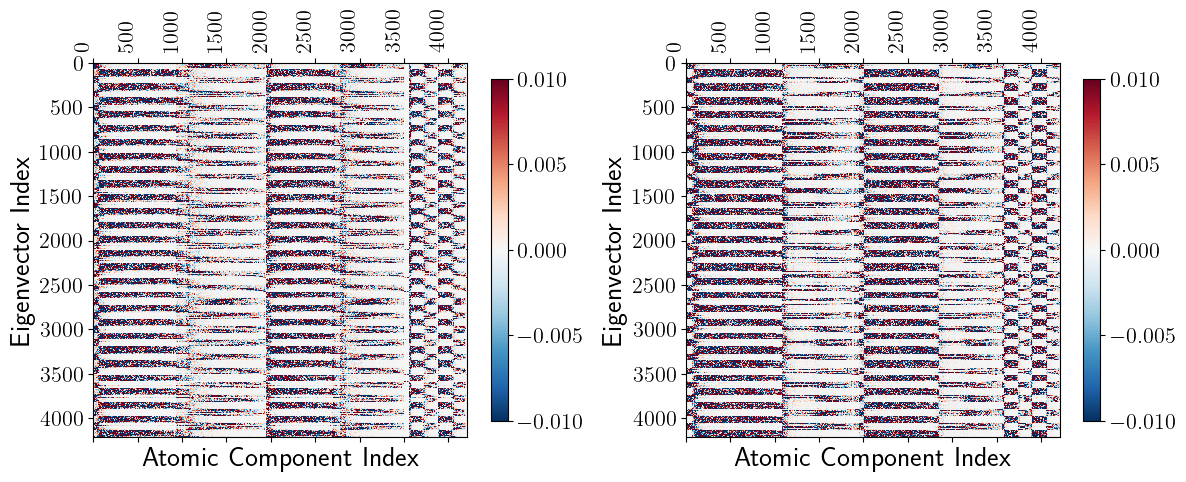

In [ ]:
# need to regroup the entries in the eigenvectors according to the atomic species, so that we can visualise the contribution of each atomic species to each eigenvector. The current order of the entries in the eigenvectors is according to the order of the atoms in the equilibrium structure, which is Li, P, S, Cl. We want to reorder the entries so that they are grouped by atomic species, i.e. all Li entries first, then all P entries, then all S entries, and finally all Cl entries.
input_atom_order = averaged_structure.get_chemical_symbols()
input_atom_oder_dict = {i: symbol for i, symbol in enumerate(input_atom_order)}
reordered_indicies = []
for symbols in ['Li', 'S', 'P', 'Cl']:
    indices = [i for i, symbol in input_atom_oder_dict.items() if symbol == symbols]
    expanded_indices = list(np.array([[3*i, 3*i+1, 3*i+2] for i in indices]).reshape(-1))
    
    reordered_indicies += expanded_indices
    print(symbols, len(reordered_indicies))
   

reordered_eigenvectors_200K = np.zeros_like(eigenvectors_200K)
reordered_eigenvectors_600K = np.zeros_like(eigenvectors_600K)

for i in range(eigenvectors_200K.shape[0]):
    reordered_eigenvectors_200K[i] = eigenvectors_200K[i][reordered_indicies]
    reordered_eigenvectors_600K[i] = eigenvectors_600K[i][reordered_indicies]

import matplotlib.colors as colors

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
cax=ax[0].matshow(reordered_eigenvectors_200K,cmap='RdBu_r',vmin=-0.01, vmax=0.01)
#ax.tick_params(top=False, labeltop=False) 
plt.setp(ax[0].get_xticklabels(), rotation='vertical', ha='right')

ax[0].set_ylabel('Eigenvector Index')
ax[0].set_xlabel('Atomic Component Index')
fig.colorbar(cax,shrink=0.6)

cax=ax[1].matshow(reordered_eigenvectors_600K,cmap='RdBu_r',vmin=-0.01, vmax=0.01)
#ax.tick_params(top=False, labeltop=False) 
plt.setp(ax[1].get_xticklabels(), rotation='vertical', ha='right')

ax[1].set_ylabel('Eigenvector Index')
ax[1].set_xlabel('Atomic Component Index')
fig.colorbar(cax,shrink=0.6)
plt.tight_layout()
plt.show()

In [123]:
xs_200K=[]
ys_200K=[]
xs_600K=[]
ys_600K=[]  
for i in _progress(range(0,len(atomic_displacements),10), desc="Projecting trajectory data", leave=False):
    projection_1_200K = np.dot(atomic_displacements[i], eigenvectors_200K[:, 0])
    projection_2_200K = np.dot(atomic_displacements[i], eigenvectors_200K[:, second_index])
    xs_200K.append(projection_1_200K)
    ys_200K.append(projection_2_200K)

    projection_1_600K = np.dot(atomic_displacements[i], eigenvectors_600K[:, 0])
    projection_2_600K = np.dot(atomic_displacements[i], eigenvectors_600K[:, second_index])
    xs_600K.append(projection_1_600K)
    ys_600K.append(projection_2_600K)

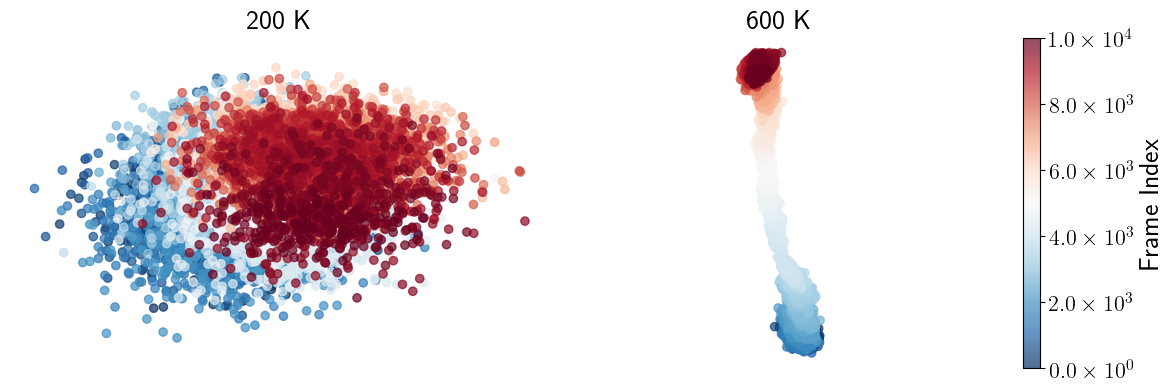

In [124]:
import matplotlib.colors as colors
import matplotlib.ticker as ticker

def fmt(x, pos):
    a, b = '{:.1e}'.format(x).split('e')
    b = int(b)
    return r'${} \times 10^{{{}}}$'.format(a, b)


seq = np.arange(len(xs_200K))
#seq = system_energies
plt.subplots(1, 2, figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.scatter(xs_200K, ys_200K, c=seq, cmap='RdBu_r', norm=colors.Normalize(vmin=min(seq), vmax=max(seq)), alpha=0.7)
#plt.colorbar(label='Frame Index')
plt.title('200 K')
plt.axis('equal')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.scatter(xs_600K, ys_600K, c=seq, cmap='RdBu_r', norm=colors.Normalize(vmin=min(seq), vmax=max(seq)), alpha=0.7)
plt.colorbar(label='Frame Index',format=ticker.FuncFormatter(fmt))
plt.title('600 K')
plt.axis('equal')
plt.axis('off')

plt.tight_layout()